# Handwritten Digit Recognition (0–9) with K-Nearest Neighbours

A supervised learning project that classifies 8×8 grayscale images of handwritten digits.

### Before you run: Google Drive setup
Upload the project to Google Drive with this layout:
```
My Drive/
├── Colab Notebooks/
│   └── Classification_KNN.ipynb
└── workshop/
    └── classification/
        └── digits_data.zip     (contains images/ and digits.csv)
```


## 1. Problem Statement

Handwritten digits vary from person to person: the same digit can be written thicker, thinner, slanted or shifted. A system that reads digits (postal codes, bank cheques, forms) must recognise the digit **despite** this variation.

**Task:** given an 8×8 grayscale image of a single handwritten digit, predict which digit (0–9) it shows.

| | |
|---|---|
| **Type of problem** | Supervised learning, multi-class classification (10 classes) |
| **Input (X)** | 64 pixel values (8 × 8 image), each an ink intensity from 0 to 16 |
| **Output (y)** | The digit label: 0, 1, 2, …, 9 |
| **Model** | K-Nearest Neighbours (KNN) |
| **Success metric** | Accuracy on a held-out test set, plus per-class precision / recall and a confusion matrix |

## 2. Dataset

**Source:** *Optical Recognition of Handwritten Digits* (UCI Machine Learning Repository), the same data as scikit-learn's `load_digits`.

Each digit was scanned as a 32×32 black-and-white bitmap, divided into 4×4 blocks, and the ink pixels in each block were counted. The result is an **8×8 image in which every pixel is a count from 0 to 16**.

| Item | Description |
|---|---|
| `images/0/` … `images/9/` | 1,797 PNG images, one folder per digit. The **folder name is the label**. |
| File names | `<digit>_<index>.png`, e.g. `3_0042.png`. `<index>` is the row number in `digits.csv`. |
| Image format | 8×8 pixels, grayscale, **inverted** for viewing: white background, dark ink |
| `digits.csv` | The same digits as a table: 64 columns `pixel_<row>_<col>` (0–16) and a `target` column |

The **images are the data source** for this notebook. `digits.csv` is only used to check that the images were loaded correctly.

In [ ]:
from google.colab import drive
# Run this cell to officially mount your Drive and grant permissions
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!unzip -qo "/content/drive/MyDrive/workshop/classification/digits_data.zip" -d /content/data
!ls /content/data

digits.csv  images


## 3. Loading the Data

### 3.1 Imports and configuration

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# Data is unzipped from Drive into Colab's local disk (run the unzip cell first)
BASE_DIR     = Path("/content/data")
DATA_DIR     = BASE_DIR / "images"
CSV_PATH     = BASE_DIR / "digits.csv"
TEST_SIZE    = 0.20    # 20% of every class goes to the test set
RANDOM_STATE = 42    # fixes all randomness -> same results every run
CLASSES      = list(range(10))

In [ ]:
print("Drive mounted   :", Path("/content/drive/MyDrive").exists())
print("BASE_DIR exists :", BASE_DIR.exists(), "->", BASE_DIR)
print("DATA_DIR exists :", DATA_DIR.exists(), "->", DATA_DIR)
if DATA_DIR.exists():
    print("Found classes in DATA_DIR:", sorted([p.name for p in DATA_DIR.iterdir() if p.is_dir()]))

Drive mounted   : True
BASE_DIR exists : True -> /content/data
DATA_DIR exists : True -> /content/data/images
Found classes in DATA_DIR: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


### 3.2 Load the images from the class folders
For every PNG in `images/<digit>/`:
1. read it with `plt.imread` and convert it to grayscale 0–255 (255 = white),
2. **undo the inversion** and map it back to the original 0–16 scale: `pixel = round((255 − png_value) / 16)`,
3. take the label from the **folder name**.

Only `[0-9]/*.png` is matched.

In [ ]:
def read_png_0_16(path):
    # Reads a PNG and returns it on the original 0-16 ink scale (0 = background)
    png = plt.imread(path).astype(np.float64)   # values 0.0-1.0
    if png.ndim == 3:                           # colour image -> grayscale
        png = png[..., :3].mean(axis=2)
    png = np.round(png * 255.0)                 # back to 0-255 (255 = white)
    return np.round((255.0 - png) / 16.0)       # invert + rescale to 0-16

def load_image_folder(data_dir):
    # Returns images (n, 8, 8), labels (n,) and file paths
    paths = sorted(data_dir.glob("[0-9]/*.png"))
    images = np.stack([read_png_0_16(p) for p in paths])
    labels = np.array([int(p.parent.name) for p in paths])   # label = folder name
    return images, labels, paths

images, y, paths = load_image_folder(DATA_DIR)
X = images.reshape(len(images), -1)   # flatten each 8x8 image into 64 features

print(f"Images loaded : {len(images)}")
print(f"Image shape   : {images.shape[1:]}  ->  {X.shape[1]} features")
print(f"Classes       : {np.unique(y).tolist()}")
print(f"Pixel range   : {X.min():.0f} to {X.max():.0f}")

Images loaded : 1797
Image shape   : (8, 8)  ->  64 features
Classes       : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Pixel range   : 0 to 16


In [ ]:
paths = sorted(DATA_DIR.glob("[0-9]/*.png"))
print(paths[0:10])
print(type(paths))
print(len(paths),"\n")
labels = np.array([int(p.parent.name) for p in paths])
print(labels)
print(type(labels))
print(len(labels),"\n")
images = np.stack([read_png_0_16(p) for p in paths])
print(type(images))
print(images.shape)
print(len(images))
print(images[0])

[PosixPath('/content/data/images/0/0_0000.png'), PosixPath('/content/data/images/0/0_0010.png'), PosixPath('/content/data/images/0/0_0020.png'), PosixPath('/content/data/images/0/0_0030.png'), PosixPath('/content/data/images/0/0_0036.png'), PosixPath('/content/data/images/0/0_0048.png'), PosixPath('/content/data/images/0/0_0049.png'), PosixPath('/content/data/images/0/0_0055.png'), PosixPath('/content/data/images/0/0_0072.png'), PosixPath('/content/data/images/0/0_0078.png')]
<class 'list'>
1797 

[0 0 0 ... 9 9 9]
<class 'numpy.ndarray'>
1797 

<class 'numpy.ndarray'>
(1797, 8, 8)
1797
[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]


### 3.3 Check against `digits.csv`
The number in each file name is its row in `digits.csv`, so every image must match that row exactly.

In [ ]:
df = pd.read_csv(CSV_PATH)
row_idx = np.array([int(p.stem.split("_")[1]) for p in paths])

pixels_match = np.array_equal(X, df.drop(columns="target").to_numpy()[row_idx])
labels_match = np.array_equal(y, df["target"].to_numpy()[row_idx])
print("Pixels identical to digits.csv :", pixels_match)
print("Labels identical to digits.csv :", labels_match)
assert pixels_match and labels_match, "Images were not loaded correctly"

Pixels identical to digits.csv : True
Labels identical to digits.csv : True


## 4. Exploratory Data Analysis (EDA)

### 4.1 Class distribution

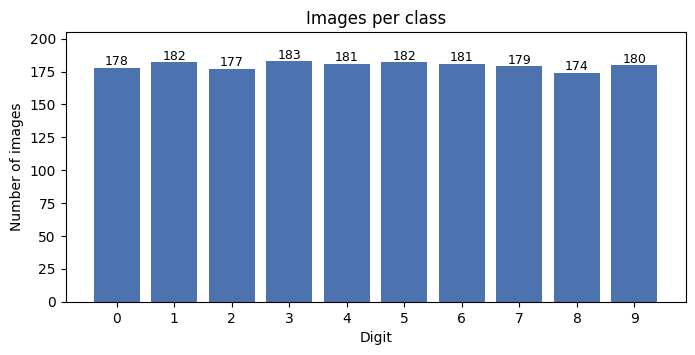

Smallest class: 8 (174)   Largest class: 3 (183)   Ratio: 1.05


In [ ]:
counts = pd.Series(y).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(counts.index, counts.values, color="#4C72B0")
for d, c in counts.items():
    ax.text(d, c + 2, str(c), ha="center", fontsize=9)
ax.set_xticks(CLASSES)
ax.set_xlabel("Digit")
ax.set_ylabel("Number of images")
ax.set_title("Images per class")
ax.set_ylim(0, counts.max() * 1.12)
plt.show()

print(f"Smallest class: {counts.idxmin()} ({counts.min()})   "
      f"Largest class: {counts.idxmax()} ({counts.max()})   "
      f"Ratio: {counts.max() / counts.min():.2f}")

The classes are **almost perfectly balanced** (about 180 images each), so accuracy is a fair metric. The split must keep this balance in both train and test (Section 6).

### 4.2 Sample images from each class

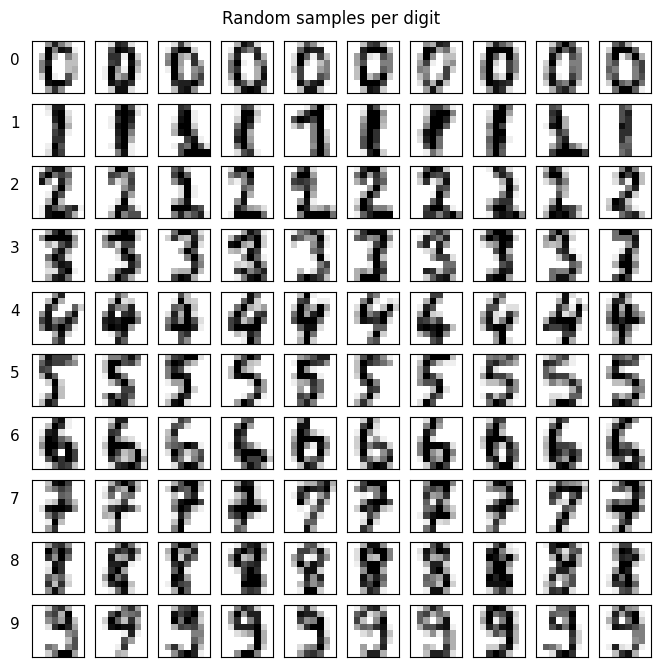

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
fig, axes = plt.subplots(10, 10, figsize=(8, 8))
for digit in CLASSES:
    picks = rng.choice(np.flatnonzero(y == digit), size=10, replace=False)
    for col, i in enumerate(picks):
        ax = axes[digit, col]
        ax.imshow(images[i], cmap="gray_r", vmin=0, vmax=16)
        ax.set_xticks([]); ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(digit, rotation=0, labelpad=12, fontsize=11)
fig.suptitle("Random samples per digit", y=0.92)
plt.show()

The digits are readable even at 8×8, but handwriting varies a lot within each class (thickness, slant, position).

### 4.3 The average digit of each class

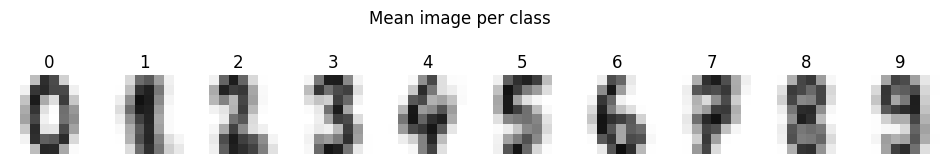

In [ ]:
fig, axes = plt.subplots(1, 10, figsize=(12, 1.8))
for digit, ax in zip(CLASSES, axes):
    ax.imshow(images[y == digit].mean(axis=0), cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(digit)
    ax.axis("off")
fig.suptitle("Mean image per class", y=1.08)
plt.show()

The average shapes are clearly different, so images of the same digit tend to be **close to each other** in pixel space, which is exactly what KNN relies on.

### 4.4 Pixel intensity distribution

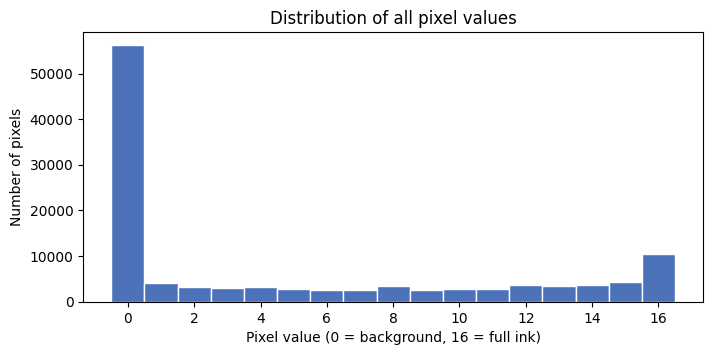

Background pixels (0): 48.9%   Full-ink pixels (16): 9.1%


In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(X.ravel(), bins=np.arange(-0.5, 17.5, 1), color="#4C72B9", edgecolor="white")
ax.set_xlabel("Pixel value (0 = background, 16 = full ink)")
ax.set_ylabel("Number of pixels")
ax.set_title("Distribution of all pixel values")
ax.set_xticks(range(0, 17, 2))
plt.show()

print(f"Background pixels (0): {np.mean(X == 0):.1%}   Full-ink pixels (16): {np.mean(X == 16):.1%}")

About **half of all pixels are background (0)**. Ink values 1–15 are spread fairly evenly, with a second peak at **16**. All 64 features share the **same 0–16 scale**, which matters for a distance-based model.

### 4.5 Which digits look alike?





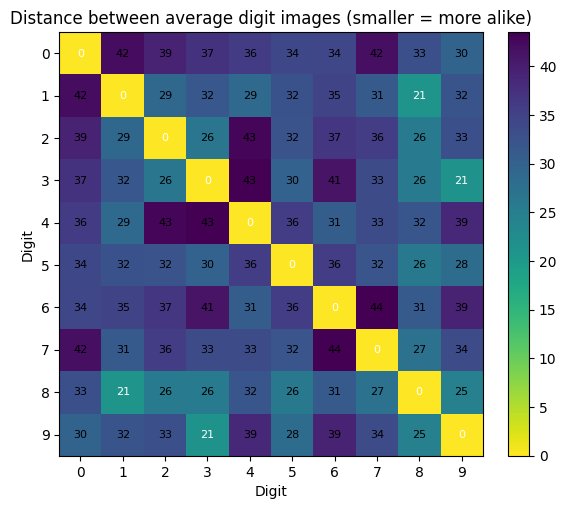

Most similar pairs : [(1, 8), (3, 9), (8, 9)]
Most different pairs: [(2, 4), (3, 4), (6, 7)]


In [ ]:
class_means = np.stack([X[y == d].mean(axis=0) for d in CLASSES])            # 10 x 64
dist = np.sqrt(((class_means[:, None] - class_means[None]) ** 2).sum(axis=2))  # 10 x 10

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(dist, cmap="viridis_r")
for r in CLASSES:
    for c in CLASSES:
        ax.text(c, r, f"{dist[r, c]:.0f}", ha="center", va="center", fontsize=8,
                color="white" if dist[r, c] < dist.max() / 2 else "black")
ax.set_xticks(CLASSES); ax.set_yticks(CLASSES)
ax.set_xlabel("Digit"); ax.set_ylabel("Digit")
ax.set_title("Distance between average digit images (smaller = more alike)")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.show()

pairs = [(dist[a, b], a, b) for a in CLASSES for b in CLASSES if a < b]
print("Most similar pairs :", [(a, b) for _, a, b in sorted(pairs)[:3]])
print("Most different pairs:", [(a, b) for _, a, b in sorted(pairs)[-3:]])

The most similar pairs are **1 & 8** and **3 & 9**, followed by 8 & 9. The most different are **2 & 4**, **3 & 4** and **6 & 7**. These similar pairs are where we expect KNN to make its few mistakes, and one of the test errors is indeed an 8 predicted as a 1.

### EDA summary
| Finding | Consequence |
|---|---|
| 10 balanced classes (~180 images each) | Accuracy is a fair metric; the split must be stratified |
| All features on the same 0–16 scale | KNN can use the pixels directly; dividing by 16 is enough |
| Average digits differ, some pairs are close (1 & 8, 3 & 9) | KNN should work well; mistakes expected between similar digits |

## 5. Approach to Training

**How KNN works:** it memorises the training images. To classify a new image it finds the **k** most similar training images (smallest distance between their 64 pixel values) and returns their **majority label**.

| Step | What we do | Why |
|---|---|---|
| 1. Split | Stratified 80% train / 20% test, written from scratch | The test set simulates unseen handwriting and keeps the class balance |
| 2. Scale | Divide every pixel by 16 (range 0–1) | All pixels share one unit, so a fixed division is enough |
| 3. Baseline | KNN with default `k = 5` | A reference point |
| 4. Tune | 5-fold cross-validation **on the training set only** over `k`, `weights` and distance metric `p` | Chooses settings without looking at the test set |
| 5. Evaluate | Use the test set **once** with the best model | An honest estimate of performance on new data |

**Hyperparameters**
- **k (`n_neighbors`)**: small k follows the data closely; large k smooths decisions but can blur nearby classes.
- **weights**: `uniform` (every neighbour one vote) or `distance` (closer neighbours count more).
- **p**: `1` = Manhattan distance, `2` = Euclidean distance.

## 6. Train / Test Split

### 6.1 The problem with splitting manually
The images are stored **grouped by class**. Splitting them by hand (moving files into folders, or taking the first 80% of the list) causes:

| Problem | What goes wrong |
|---|---|
| **Order bias** | The list is sorted by class, so "first 80% = train" leaves whole digits out of train or test |
| **Class imbalance** | A random cut can under-represent some digits in the test set |
| **Not reproducible** | A hand-made split can't be recreated exactly |
| **Human error** | Files can end up in both sets (leakage) or in neither |

The cell below shows the order-bias problem:

In [ ]:
cut = int(len(y) * (1 - TEST_SIZE))
naive = pd.DataFrame({
    "train (first 80%)": pd.Series(y[:cut]).value_counts(),
    "test (last 20%)":   pd.Series(y[cut:]).value_counts(),
}).reindex(CLASSES).fillna(0).astype(int)
naive.index.name = "digit"
naive.T

digit,0,1,2,3,4,5,6,7,8,9
train (first 80%),178,182,177,183,181,182,181,173,0,0
test (last 20%),0,0,0,0,0,0,0,6,174,180


Digits 0–6 never appear in the test set and 8–9 never appear in training, so any accuracy measured this way would be meaningless.

### 6.2 Solution: a stratified, shuffled, reproducible split
1. Group the image indices **by class**.
2. **Shuffle** each group with a seeded random generator (removes order bias, reproducible).
3. Send `round(TEST_SIZE × class_size)` images of each class to test, the rest to train (**stratification**).
4. Shuffle the final train and test lists so classes are mixed.

In [ ]:
def stratified_train_test_split(labels, test_size=0.2, seed=42):
    # Returns (train_idx, test_idx): positions into `labels`, split per class
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for cls in np.unique(labels):
        cls_idx = np.flatnonzero(labels == cls)   # all samples of this class
        rng.shuffle(cls_idx)                      # remove order bias
        n_test = int(round(len(cls_idx) * test_size))
        test_idx.extend(cls_idx[:n_test])
        train_idx.extend(cls_idx[n_test:])
    train_idx, test_idx = np.array(train_idx), np.array(test_idx)
    rng.shuffle(train_idx)                        # mix classes together
    rng.shuffle(test_idx)
    return train_idx, test_idx

train_idx, test_idx = stratified_train_test_split(y, test_size=TEST_SIZE, seed=RANDOM_STATE)

X_train, y_train = X[train_idx], y[train_idx]
X_test,  y_test  = X[test_idx],  y[test_idx]
print(f"Train: {len(train_idx)} images   Test: {len(test_idx)} images   "
      f"({len(test_idx) / len(y):.1%} test)")

split_table = pd.DataFrame({
    "train": pd.Series(y_train).value_counts(),
    "test":  pd.Series(y_test).value_counts(),
}).reindex(CLASSES)
split_table["total"]  = split_table["train"] + split_table["test"]
split_table["test %"] = (100 * split_table["test"] / split_table["total"]).round(1)
split_table.index.name = "digit"
split_table

Train: 1438 images   Test: 359 images   (20.0% test)


,train,test,total,test %
digit,,,,
0,142,36,178,20.2
1,146,36,182,19.8
2,142,35,177,19.8
3,146,37,183,20.2
4,145,36,181,19.9
5,146,36,182,19.8
6,145,36,181,19.9
7,143,36,179,20.1
8,139,35,174,20.1


### 6.3 Verifying the split

In [ ]:
# 1. No image is in both sets (no leakage)
assert len(np.intersect1d(train_idx, test_idx)) == 0
# 2. Every image is used exactly once
assert np.array_equal(np.sort(np.concatenate([train_idx, test_idx])), np.arange(len(y)))
# 3. Reproducible: the same seed gives the same split
again_train, again_test = stratified_train_test_split(y, TEST_SIZE, RANDOM_STATE)
assert np.array_equal(again_train, train_idx) and np.array_equal(again_test, test_idx)
# 4. Stratified: every class keeps (almost) the same share in train and test


#extra
share = pd.DataFrame({
    "all %":   pd.Series(y).value_counts(normalize=True) * 100,
    "train %": pd.Series(y_train).value_counts(normalize=True) * 100,
    "test %":  pd.Series(y_test).value_counts(normalize=True) * 100,
    "train n": pd.Series(y_train).value_counts(),
    "test n":  pd.Series(y_test).value_counts(),
}).reindex(CLASSES)
share.index.name = "digit"
assert (share["test %"] - share["all %"]).abs().max() < 1.0

print("All checks passed: no overlap, nothing lost, reproducible, stratified.")
share.round(2)

All checks passed: no overlap, nothing lost, reproducible, stratified.


,all %,train %,test %,train n,test n
digit,,,,,
0,9.91,9.87,10.03,142,36
1,10.13,10.15,10.03,146,36
2,9.85,9.87,9.75,142,35
3,10.18,10.15,10.31,146,37
4,10.07,10.08,10.03,145,36
5,10.13,10.15,10.03,146,36
6,10.07,10.08,10.03,145,36
7,9.96,9.94,10.03,143,36
8,9.68,9.67,9.75,139,35


## 7. Training the KNN Classifier

### 7.1 Scaling
Every pixel is divided by 16 (the known maximum), so features lie between 0 and 1. Nothing is learned from the data, so this cannot leak information from the test set.

In [ ]:
X_train_s = X_train / 16.0
X_test_s  = X_test / 16.0

### 7.2 Baseline model
KNN with default settings (`k = 5`), scored with 5-fold cross-validation **on the training set**.

In [ ]:
# 5 folds of the training set; each fold keeps the same mix of digits
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Baseline: default KNN (k = 5, Euclidean distance, equal votes)
baseline = KNeighborsClassifier(n_neighbors=5)

# Train on 4 folds, score on the 5th, repeat 5 times (test set not used)
baseline_scores = cross_val_score(baseline, X_train_s, y_train, cv=cv, scoring="accuracy")

print("Accuracy per fold:", np.round(baseline_scores, 4))
print(f"Mean CV accuracy : {baseline_scores.mean():.4f} ± {baseline_scores.std():.4f}")   # mean ± spread

Accuracy per fold: [0.9792 0.9826 0.9896 0.9756 0.9895]
Mean CV accuracy : 0.9833 ± 0.0056


### 7.3 Hyperparameter tuning with cross-validation
`GridSearchCV` tries every combination below with 5-fold cross-validation on the training set. The test set is **not** used here.

In [ ]:
param_grid = {
    "n_neighbors": list(range(1, 16)),
    "weights":     ["uniform", "distance"],
    "p":           [1, 2],               # 1 = Manhattan, 2 = Euclidean
}

search = GridSearchCV(KNeighborsClassifier(), param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
search.fit(X_train_s, y_train)

print(f"Best parameters  : {search.best_params_}")
print(f"Best CV accuracy : {search.best_score_:.4f}")

Best parameters  : {'n_neighbors': 1, 'p': 2, 'weights': 'uniform'}
Best CV accuracy : 0.9875


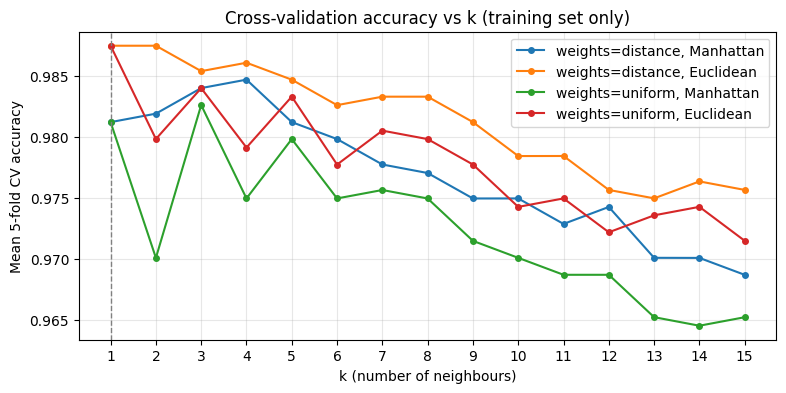

In [ ]:
res = pd.DataFrame(search.cv_results_)
fig, ax = plt.subplots(figsize=(9, 4))
for (weights, p), grp in res.groupby(["param_weights", "param_p"]):
    grp = grp.sort_values("param_n_neighbors")
    ax.plot(grp["param_n_neighbors"], grp["mean_test_score"], marker="o", ms=4,
            label=f"weights={weights}, {'Manhattan' if p == 1 else 'Euclidean'}")
ax.axvline(search.best_params_["n_neighbors"], color="grey", ls="--", lw=1)
ax.set_xlabel("k (number of neighbours)")
ax.set_ylabel("Mean 5-fold CV accuracy")
ax.set_title("Cross-validation accuracy vs k (training set only)")
ax.set_xticks(range(1, 16))
ax.legend()
ax.grid(alpha=0.3)
plt.show()

- **Distance-weighted Euclidean** is the best or joint-best curve at almost every k.
- Accuracy is highest for **small k** and drifts down as k grows, because more neighbours from nearby *other* digits get a vote.
- With `uniform` votes, **even values of k dip** because the neighbours can split into a tie.
- **k = 1** with Euclidean distance wins, tied with distance-weighted k = 2. The spread between the top settings is under 1%, so the model is not very sensitive to the exact choice.

## 8. Evaluation on the Test Set
`GridSearchCV` has already re-trained the best settings on the whole training set. Now the test set is used for the first and only time.

In [ ]:
model = search.best_estimator_
y_pred = model.predict(X_test_s)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}  ({(y_pred == y_test).sum()} / {len(y_test)} correct)")
print()
print(classification_report(y_test, y_pred, digits=3))

Test accuracy: 0.9916  (356 / 359 correct)

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        36
           1      0.973     1.000     0.986        36
           2      1.000     1.000     1.000        35
           3      1.000     1.000     1.000        37
           4      1.000     1.000     1.000        36
           5      1.000     0.944     0.971        36
           6      0.973     1.000     0.986        36
           7      1.000     1.000     1.000        36
           8      1.000     0.971     0.986        35
           9      0.973     1.000     0.986        36

    accuracy                          0.992       359
   macro avg      0.992     0.992     0.992       359
weighted avg      0.992     0.992     0.992       359



### 8.1 Confusion matrix
Rows are the true digits, columns the predicted digits. Everything off the diagonal is a mistake.

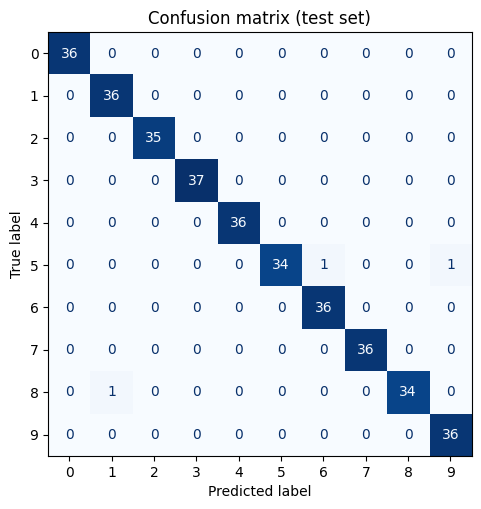

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Confusion matrix (test set)")
plt.show()

### 8.2 Misclassified images

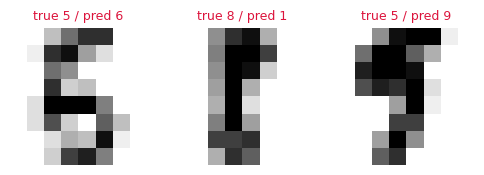

In [ ]:
wrong = np.flatnonzero(y_pred != y_test)
fig, axes = plt.subplots(1, len(wrong), figsize=(2 * len(wrong), 2.4), squeeze=False)
for ax, i in zip(axes.ravel(), wrong):
    ax.imshow(X_test[i].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(f"true {y_test[i]} / pred {y_pred[i]}", fontsize=9, color="crimson")
    ax.axis("off")
plt.show()

The mistakes are unusual handwriting that genuinely looks like the predicted digit at 8×8 resolution: a 5 with a closed loop like a 6, a very thin 8 that is just a vertical stroke, and a 5 with a top loop like a 9.

## 9. Conclusion

| | |
|---|---|
| Dataset | 1,797 images, 8×8, 10 classes |
| Split | 1,438 train / 359 test (stratified, seed 42) |
| Baseline (k = 5) | 98.33% cross-validation accuracy |
| Best settings | k = 1, Euclidean distance |
| Best cross-validation accuracy | 98.75% |
| **Test accuracy** | **99.16%** (356 / 359 correct) |

- A K-Nearest Neighbours classifier recognises 8×8 handwritten digits with **about 99% accuracy** on images it has never seen. The cross-validation and test scores agree, so the model generalises.
- Splitting by hand gives a biased, meaningless test set. The from-scratch **stratified split** shuffles within each class with a fixed seed, keeps every digit's share equal in train and test, and is checked by asserts.
- The remaining errors are between digits that look alike at this low resolution.

**Limitations and next steps**
- KNN compares each new image with every training image, so it gets slow on large datasets, and it only measures pixel-by-pixel similarity, not shape.
- Compare with other models (Logistic Regression, SVM, Random Forest) on the same split, or try a small CNN for larger images.